# 数値の変数と生存の関係
年齢や運賃などの数値の変数と生存の関係を、ヒストグラムの重ね描きと区間ごとの生存率で調べます。平均や相関係数だけでは見落とす関係があることを確かめます。

## 学習目標
- 生存したかどうかで分けて、数値の変数の分布を重ねて比べられる
- `pd.cut`(区切りを指定)と `pd.qcut`(人数が等しくなるように区切る)で区間に分け、区間ごとの生存率を求められる
- 平均や相関係数では見えない関係(曲線的な関係)があることを説明できる

## 平均だけでは見えない関係

生存した乗客と死亡した乗客で、年齢の要約統計量を比べます。

In [1]:
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 死亡(0)・生存(1)のグループごとに、年齢の要約統計量を求める
train.groupby("Survived")["Age"].describe().round(2)

          count   mean    std   min   25%   50%    75%   max
Survived                                                    
0         428.0  30.77  14.05  0.75  21.0  28.5  39.25  71.0
1         290.0  30.04  14.83  0.67  20.0  29.0  39.00  76.0


平均は 30.8 歳と 30.0 歳で、ほとんど差がありません。では、年齢は生存と関係がないのでしょうか。分布を重ねて描いてみます。

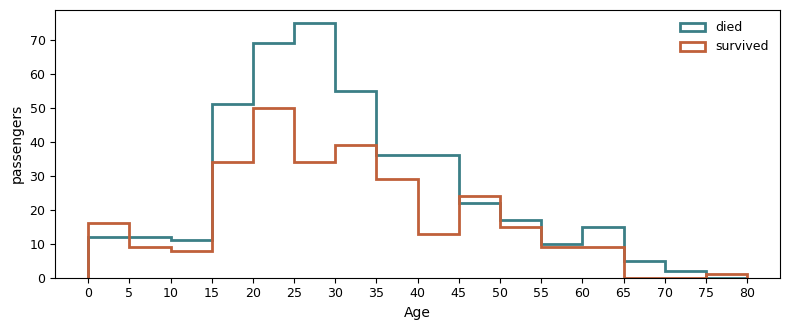

In [2]:
import matplotlib.pyplot as plt

# 柱の区切りを 0, 5, 10, ..., 80 歳にする(range(0, 81, 5) は 0 から 80 まで 5 刻み)
bins = list(range(0, 81, 5))

# 死亡した乗客・生存した乗客の年齢をそれぞれ取り出す
# (train.loc[条件, 列名] で、条件に合う行の指定した列を取り出す)
age_died = train.loc[train["Survived"] == 0, "Age"].dropna()
age_survived = train.loc[train["Survived"] == 1, "Age"].dropna()

fig, ax = plt.subplots(figsize=(8, 3.4))
# 2 つのヒストグラムを重ねて描く。重なっても見えるように、柱を塗りつぶさず輪郭線(step)で描く
ax.hist(age_died, bins=bins, histtype="step", linewidth=2, label="died")
ax.hist(age_survived, bins=bins, histtype="step", linewidth=2, label="survived")
ax.set_xticks(bins)        # 目盛りを柱の区切りに合わせる
ax.set_xlabel("Age")
ax.set_ylabel("passengers")
ax.legend()                # label に書いた名前で凡例を表示する
fig.tight_layout()
plt.show()

0〜5 歳では生存した乗客(オレンジ)の方が多く、20〜35 歳では死亡した乗客(青緑)がずっと多いことがわかります。年齢によって生存のしやすさが変わるものの、「年齢が高いほど生存しやすい(しにくい)」という一方向の関係ではないため、平均や相関係数には表れにくいのです。

## 区間に分けて生存率を求める

`pd.cut` で年齢を区間に分け、区間ごとの生存率を求めます。区間 `(0, 10]` は「0 より大きく 10 以下」を表します。欠損値はどの区間にも入りません。

In [3]:
# 年齢を、区切り 0, 10, 20, 40, 60, 80 で区間に分ける(各乗客がどの区間に入るかを表す列ができる)
age_group = pd.cut(train["Age"], bins=[0, 10, 20, 40, 60, 80])

# 区間ごとのグループに分け、生存率と人数を求める
# (observed=True は、該当者のいない区間を表示しないための指定)
train.groupby(age_group, observed=True)["Survived"].agg(["mean", "count"]).round(3)

           mean  count
Age                   
(0, 10]   0.472     53
(10, 20]  0.426    115
(20, 40]  0.390    382
(40, 60]  0.427    143
(60, 80]  0.240     25


10 歳以下の生存率は 47% と高く、60 歳を超えると 24% に下がります。

運賃のように偏りの大きい変数は、`pd.qcut` で **人数がほぼ等しくなるように** 区切ると比べやすくなります。`pd.qcut(列, 5)` は 5 等分(五分位)です。

In [4]:
# 運賃を、人数がほぼ等しい 5 つの区間に分ける
fare_group = pd.qcut(train["Fare"], 5)

# 区間ごとの生存率と人数を求める
train.groupby(fare_group, observed=True)["Survived"].agg(["mean", "count"]).round(3)

                   mean  count
Fare                          
(-0.001, 7.829]   0.268    179
(7.829, 10.5]     0.215    186
(10.5, 22.425]    0.385    169
(22.425, 46.94]   0.393    178
(46.94, 512.329]  0.618    178


運賃が高い区間ほど生存率が高く、上位 20%(46.94 より高い)では 62% です。運賃は等級と強く関係しているため、等級の違いが表れていると考えられます。

## 演習

学習用のデータで、年齢 `Age` を区切り `[0, 16, 32, 48, 64, 80]` で区間に分け、区間ごとの生存率(`mean`)と人数(`count`)を小数第3位まで表示してください。

In [ ]:
# @starter
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 年齢を、指定した区切りで区間に分ける
# (____ に、区切りの値を指定して区間に分ける pandas の関数の名前を入れる)
age_group = pd.____(train["Age"], bins=[0, 16, 32, 48, 64, 80])

# 区間ごとの生存率と人数を求め、小数第3位まで表示する
result = train.groupby(age_group, observed=True)["Survived"].agg(["mean", "count"])
print(result.round(3))

In [5]:
# @solution
# @title: 年齢の区間ごとの生存率
# @hint: 区切りの値を指定して区間に分けるのは pd.cut です。
# @explanation: 16 歳以下の生存率は 50% で、ほかの区間(約 38〜46%)より高くなっています。64 歳を超える乗客は 8 人と少なく、生存率 12.5% は人数が少ないため不安定な値であることにも注意しましょう。
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 年齢を、区切り 0, 16, 32, 48, 64, 80 で区間に分ける
age_group = pd.cut(train["Age"], bins=[0, 16, 32, 48, 64, 80])

# 区間ごとの生存率と人数を求め、小数第3位まで表示する
result = train.groupby(age_group, observed=True)["Survived"].agg(["mean", "count"])
print(result.round(3))

           mean  count
Age                   
(0, 16]   0.500     86
(16, 32]  0.384    357
(32, 48]  0.387    186
(48, 64]  0.457     81
(64, 80]  0.125      8


学習用のデータで、運賃 `Fare` を **人数がほぼ等しい 4 つの区間**(四分位)に分け、区間ごとの生存率(`mean`)と人数(`count`)を小数第3位まで表示してください。

In [ ]:
# @starter
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 運賃を、人数がほぼ等しい 4 つの区間に分ける(____ に、区間に分ける式を書く)
fare_group = ____

# 区間ごとの生存率と人数を求め、小数第3位まで表示する
result = train.groupby(fare_group, observed=True)["Survived"].agg(["mean", "count"])
print(result.round(3))

In [6]:
# @solution
# @title: 運賃の四分位ごとの生存率
# @hint: pd.qcut(列, 区間の数) で、人数がほぼ等しくなるように区切れます。
# @explanation: 運賃の最も低い区間の生存率は約 23%、最も高い区間は約 57% で、運賃が高いほど生存率が高くなっています。
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 運賃を、人数がほぼ等しい 4 つの区間(四分位)に分ける
fare_group = pd.qcut(train["Fare"], 4)

# 区間ごとの生存率と人数を求め、小数第3位まで表示する
result = train.groupby(fare_group, observed=True)["Survived"].agg(["mean", "count"])
print(result.round(3))

                  mean  count
Fare                         
(-0.001, 7.896]  0.226    239
(7.896, 14.254]  0.306    206
(14.254, 31.5]   0.399    223
(31.5, 512.329]  0.572    222


<!-- @question
type: choice
answer: 相関係数は直線的な関係の強さを表すもので、子どもで生存率が高いような一方向でない関係は小さく表れるため。
title: 相関係数と年齢の関係
hint: 相関係数が表すのはどのような関係の強さか、また年齢と生存率はどのような関係だったかを思い出しましょう。
explanation: 相関係数は直線的(一方向)な関係の強さを表します。年齢と生存の関係は、子どもで高く、20〜30 代で低く、高齢で再び低いという一方向でない形なので、相関係数はほぼ 0 になります。相関係数が小さくても、区間に分けて調べると関係が見つかることがあります。
-->
学習用のデータで、年齢と生存(0 / 1)の相関係数は約 −0.03 とほぼ 0 だった。一方で、年齢の区間ごとの生存率には差があった。この理由として最も適切なものを選べ。

- 年齢の欠損値が多いため、区間ごとの生存率の計算が誤っているため。
- 相関係数は直線的な関係の強さを表すもので、子どもで生存率が高いような一方向でない関係は小さく表れるため。
- 相関係数は数値どうしでしか計算できず、Survived は数値ではないため。
- 相関係数がほぼ 0 なので、区間ごとの生存率の差はすべて偶然である。

## まとめ

- 平均の比較だけでなく、分布の重ね描きで違いを確認する(年齢:子どもは生存しやすく、20〜30 代は死亡が多い)。
- `pd.cut` は区切りを指定、`pd.qcut` は人数が等しくなるように区切る。区間ごとの生存率で関係の形を調べる。
- 相関係数は直線的な関係しか表さない。人数の少ない区間の生存率は不安定なので、人数も確認する。